In [1]:
import os
import random
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
import networkx as nx
import pandas as pd
import seaborn as sns

# Add project source to path
sys.path.append(
    os.path.join(
        '..',  # notes -> root
    )
)

from src.simulation.kernels import simple_kernel
import fig_settings as fs

fs.set_colors()
fs.set_fonts()

In [2]:
def hpdi(x, prob=0.5):
    """Narrowest interval containing `prob` of 1D samples."""
    x = np.sort(x)
    n = len(x)
    k = int(np.floor(prob * n))      # number of points inside the interval
    widths = x[k:] - x[:n - k]       # width of every candidate window
    i = np.argmin(widths)            # pick the narrowest
    return x[i], x[i + k]

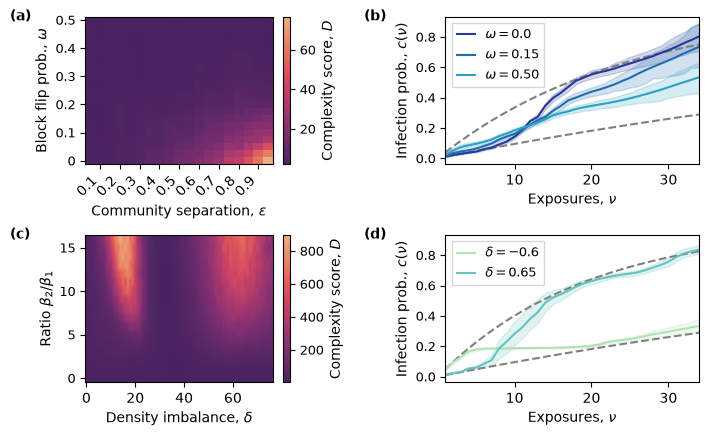

In [3]:
fig, axs = plt.subplots(
    2, 2,
    figsize=(7.0, 4.25),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1, 1.35], "wspace": 0.05},
)

# PANEL A - epsilon/omega sweep
fpath = '../results/inference_epsilon_omega_sweep/complexity_by_setting.parquet'
df = pd.read_parquet(fpath)
df_by_setting = (df.groupby(["epsilon", "omega"], as_index=False))
piv = df.pivot(index="omega", columns="epsilon", values="complexity_mean")

ax_a = axs[0,0]
im = ax_a.imshow(piv, cmap=fs.complexity_cmap, aspect="auto")

# axes
ax_a.set_xlabel("Community separation, $\\varepsilon$")
ax_a.set_ylabel("Block flip prob., $\\omega$")
ax_a.invert_yaxis()

# ticks
ax_a.set_xticks(np.arange(len(piv.columns))[1::2])
ax_a.set_xticklabels([f"{b:.3g}" for b in piv.columns[1::2]], rotation=45, ha="right")

ax_a.set_yticks(np.arange(len(piv.index))[::4])
ax_a.set_yticklabels([f"{d:.3g}" for d in piv.index[::4]])

# colorbar
fig.colorbar(im, ax=ax_a, label="Complexity score, $D$")

# PANEL B - sampled kernels for varying omega
omega1_mu_draws = np.load('../results/inference_epsilon_omega_sweep/np_kernel_omega_0.0.npz')["draws_mu"][:, 0, :]
omega1_mu = np.mean(omega1_mu_draws, axis=0)
omega1_lower = np.empty(omega1_mu_draws.shape[1])
omega1_upper = np.empty(omega1_mu_draws.shape[1])
for j in range(omega1_mu_draws.shape[1]):
    omega1_lower[j], omega1_upper[j] = hpdi(omega1_mu_draws[:, j], prob=0.9)

omega2_mu_draws = np.load('../results/inference_epsilon_omega_sweep/np_kernel_omega_0.15.npz')["draws_mu"][:, 0, :]
omega2_mu = np.mean(omega2_mu_draws, axis=0)
omega2_lower = np.empty(omega2_mu_draws.shape[1])
omega2_upper = np.empty(omega2_mu_draws.shape[1])
for j in range(omega2_mu_draws.shape[1]):
    omega2_lower[j], omega2_upper[j] = hpdi(omega2_mu_draws[:, j], prob=0.9)

omega3_mu_draws = np.load('../results/inference_epsilon_omega_sweep/np_kernel_omega_0.5.npz')["draws_mu"][:, 0, :]
omega3_mu = np.mean(omega3_mu_draws, axis=0)
omega3_lower = np.empty(omega3_mu_draws.shape[1])
omega3_upper = np.empty(omega3_mu_draws.shape[1])
for j in range(omega3_mu_draws.shape[1]):
    omega3_lower[j], omega3_upper[j] = hpdi(omega3_mu_draws[:, j], prob=0.9)

kmax = np.min([len(omega1_mu), len(omega2_mu), len(omega3_mu)])
nus  = range(1, kmax+1)

ax_b = axs[0,1]
ax_b.plot(nus, simple_kernel(0.01, kmax), color='grey', linestyle='--')
ax_b.plot(nus, simple_kernel(0.04, kmax), color='grey', linestyle='--')
ax_b.fill_between(nus, omega1_lower[:kmax], omega1_upper[:kmax], color=fs.palette[5], alpha=0.2)
ax_b.plot(nus, omega1_mu[:kmax], color=fs.palette[5], label="$\\omega=0.0$")
ax_b.fill_between(nus, omega2_lower[:kmax], omega2_upper[:kmax], color=fs.palette[4], alpha=0.2)
ax_b.plot(nus, omega2_mu[:kmax], color=fs.palette[4], label="$\\omega=0.15$")
ax_b.fill_between(nus, omega3_lower[:kmax], omega3_upper[:kmax], color=fs.palette[3], alpha=0.2)
ax_b.plot(nus, omega3_mu[:kmax], color=fs.palette[3], label="$\\omega=0.50$")

# legend
ax_b.legend(handlelength=1.5, fancybox=False, fontsize=9)

# axes
ax_b.set_xlim(1, kmax)
ax_b.set_xlabel("Exposures, $\\nu$")
ax_b.set_ylabel("Infection prob., $c(\\nu)$")

# PANEL C - beta/delta sweep
fpath = '../results/inference_beta_delta_sweep/beta-delta-grid_v2.txt'
data = np.loadtxt(fpath, dtype=float)

ax_c = axs[1,0]
im = ax_c.imshow(data, cmap=fs.complexity_cmap, aspect="auto")

# axes
ax_c.set_xlabel("Density imbalance, $\\delta$")
ax_c.set_ylabel("Ratio $\\beta_2/\\beta_1$")
ax_c.invert_yaxis()

# ticks
# ax_c.set_xticks(np.arange(len(piv.columns))[1::2])
# ax_c.set_xticklabels([f"{b:.3g}" for b in piv.columns[1::2]], rotation=45, ha="right")

# ax_c.set_yticks(np.arange(len(piv.index))[::4])
# ax_c.set_yticklabels([f"{d:.3g}" for d in piv.index[::4]])

# colorbar
fig.colorbar(im, ax=ax_c, label="Complexity score, $D$")

# PANEL D - sampled kernels for varying delta
neg_delta_mu_draws = np.load('../results/inference_beta_delta_sweep/beta1-0.01_beta2-0.05_delta--0.6_epsilon-0.9_omega-0.1_rep-1.npz')["mu_post"][:, 0, :]
neg_delta_mu = np.mean(neg_delta_mu_draws, axis=0)
neg_delta_lower = np.empty(neg_delta_mu_draws.shape[1])
neg_delta_upper = np.empty(neg_delta_mu_draws.shape[1])
for j in range(neg_delta_mu_draws.shape[1]):
    neg_delta_lower[j], neg_delta_upper[j] = hpdi(neg_delta_mu_draws[:, j], prob=0.9)

pos_delta_mu_draws = np.load('../results/inference_beta_delta_sweep/beta1-0.01_beta2-0.05_delta-0.65_epsilon-0.9_omega-0.1_rep-1.npz')["mu_post"][:, 0, :]
pos_delta_mu = np.mean(pos_delta_mu_draws, axis=0)
pos_delta_lower = np.empty(pos_delta_mu_draws.shape[1])
pos_delta_upper = np.empty(pos_delta_mu_draws.shape[1])
for j in range(pos_delta_mu_draws.shape[1]):
    pos_delta_lower[j], pos_delta_upper[j] = hpdi(pos_delta_mu_draws[:, j], prob=0.9)

ax_d = axs[1,1]
ax_d.plot(nus, simple_kernel(0.01, kmax), color='grey', linestyle='--')
ax_d.plot(nus, simple_kernel(0.05, kmax), color='grey', linestyle='--')
ax_d.fill_between(nus, neg_delta_lower[:kmax], neg_delta_upper[:kmax], color=fs.palette[1], alpha=0.2)
ax_d.plot(nus, neg_delta_mu[:kmax], color=fs.palette[1], label="$\\delta=-0.6$")
ax_d.fill_between(nus, pos_delta_lower[:kmax], pos_delta_upper[:kmax], color=fs.palette[2], alpha=0.2)
ax_d.plot(nus, pos_delta_mu[:kmax], color=fs.palette[2], label="$\\delta=0.65$")

# legend
ax_d.legend(handlelength=1.5, fancybox=False, fontsize=9)

# axes
ax_d.set_xlim(1, kmax)
ax_d.sharey(ax_b)
ax_d.set_xlabel("Exposures, $\\nu$")
ax_d.set_ylabel("Infection prob., $c(\\nu)$")

# subplot labels
ax_a.text(-0.4, 1.0, "(a)", transform=ax_a.transAxes, fontweight='bold', va='center', ha='left')
ax_b.text(-0.32, 1.0, "(b)", transform=ax_b.transAxes, fontweight='bold', va='center', ha='left')
ax_c.text(-0.4, 1.0, "(c)", transform=ax_c.transAxes, fontweight='bold', va='center', ha='left')
ax_d.text(-0.32, 1.0, "(d)", transform=ax_d.transAxes, fontweight='bold', va='center', ha='left')

plt.savefig('../figs/fig2.png', dpi=300, bbox_inches='tight')
plt.show()